# Descarga y descripción de activos financieros

### CONCEPTOS TEÓRICOS

En este curso, partiremos de la premisa de que los **precios de una acción se comportan como una variable aleatoria, cuya función de distribución es lognormal**. Esta elección se justifica porque los precios no pueden ser negativos, y su comportamiento suele presentar una asimetría positiva. Además, dado que los precios de las acciones a menudo experimentan grandes fluctuaciones en el tiempo, el uso de una distribución lognormal permite capturar este comportamiento de manera más precisa. En consecuencia, asumiremos que el logaritmo de los precios sigue una distribución normal, lo cual será clave para los análisis posteriores.


Sin embargo, en lugar de trabajar directamente con precios, nos centraremos en los rendimientos. **Los rendimientos continuos de una acción, definidos como $ r_t = \ln \left( \frac{P_t}{P_{t-1}} \right) $, se aproximan a una distribución normal**. Esto nos proporciona una manera más conveniente de modelar y analizar el comportamiento de los activos financieros. **La distribución normal está caracterizada por dos parámetros fundamentales: la esperanza o media, que representa el rendimiento esperado o más probable de la acción, y la desviación estándar, que mide la dispersión de los rendimientos en torno a esa media, sirviendo como una primera aproximación al concepto de riesgo**. Cuanto mayor sea la desviación estándar, mayor será el riesgo asociado al activo.

Este enfoque nos permitirá, a lo largo del curso, modelar y simular diferentes escenarios en los que los rendimientos de una acción puedan variar en función de estos parámetros, ayudándonos a comprender mejor el equilibrio entre rentabilidad y riesgo en los mercados financieros.

### IMPLEMENTACIÓN EN PYTHON

Pandas es una librería muy popular entre los desarrolladores de Python, y sobre todo dentro del ámbito de Data Science y Machine Learning, ya que ofrece unas estructuras muy poderosas y flexibles que facilitan la manipulación y tratamiento de datos.

* Puedes encontrar la documentación de pandas [aquí](https://pandas.pydata.org/docs/index.html)
* En particular puedes ver unos tutoriales interesantes [aquí](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)

## 1. Lectura de datos

### Desde Excel y CSV

Supongamos que tenemos datos que provienen de dos **fuentes de datos distintas**, una en formato **Excel** y otra en formato **CSV**. Queremos leer ambos ficheros y unirlos con el objetivo de tener un único conjunto de datos.

<img src="https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/blob/main/Modulo_02_Aplicaciones_Financieras/imgs/data_02%20-%20Parte%201.png?raw=1">

Para poder utilizar la librería, primero hay que instalarla:

- conda install -c anaconda pandas  as pd        ##### Si usas anaconda

- pip install pandas as pd

In [1]:
import pandas as pd

In [2]:
file_path_1 = 'https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/raw/main/Modulo_02_Aplicaciones_Financieras/data/data_02%20-%20Parte%201.xlsx'

data1 = pd.read_excel(file_path_1)
data1

,Date,AAPL.O,MSFT.O
0,2010-01-01,NaN,NaN
1,2010-01-04,30.572827,30.950
2,2010-01-05,30.625684,30.960
3,2010-01-06,30.138541,30.770
4,2010-01-07,30.082827,30.452
...,...,...,...
2211,2018-06-25,182.170000,98.390
2212,2018-06-26,184.430000,99.080
2213,2018-06-27,184.160000,97.540
2214,2018-06-28,185.500000,98.630


Las estructuras que se utilizan en Pandas son:
* **DataFrame**: matriz bidimensional formado por series concatenadas en forma de filas y columnas. Cada una de las columnas es una serie
* **Series**: vector columna o matriz unidimensional que permite almacenar todo tipo de datos con un índice.
<center>
<img src="https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/blob/main/Modulo_02_Aplicaciones_Financieras/imgs/series+pandas.png?raw=1"  alt="drawing" width="40%"/>
</center>



En nuestro caso, la información se ha guardado en el dataframe llamado `data1`. Mientras que `Date`, `AAPL.O` y `MSFTO.O` son series.


<img src="https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/blob/main/Modulo_02_Aplicaciones_Financieras/imgs/Estructura%20Pandas.png?raw=1">


Voy a descargar el **dataframe** como un archivo de excel de nuevo.

- `index=False` evita que Pandas añada al Excel una columna extra con los índices `0, 1, 2, ....`

In [3]:
data1.to_excel("data1.xlsx", index=False)

In [4]:
from google.colab import files
files.download("data1.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Vamos a recuperar el archivo de manera distinta.
- Lo subimos a las carpetas creadas por googel.colab.
- Lo descargamos en nuestro notebook

,Date,AAPL.O,MSFT.O
0,2010-01-01,NaN,NaN
1,2010-01-04,30.572827,30.950
2,2010-01-05,30.625684,30.960
3,2010-01-06,30.138541,30.770
4,2010-01-07,30.082827,30.452
...,...,...,...
2211,2018-06-25,182.170000,98.390
2212,2018-06-26,184.430000,99.080
2213,2018-06-27,184.160000,97.540
2214,2018-06-28,185.500000,98.630


,Date,AAPL.O,MSFT.O
0,2010-01-01,NaN,NaN
1,2010-01-04,30.572827,30.950
2,2010-01-05,30.625684,30.960
3,2010-01-06,30.138541,30.770
4,2010-01-07,30.082827,30.452
...,...,...,...
2211,2018-06-25,182.170000,98.390
2212,2018-06-26,184.430000,99.080
2213,2018-06-27,184.160000,97.540
2214,2018-06-28,185.500000,98.630


/content
data1.xlsx  sample_data


Ahora creamos un enlace a nuestro disco-duro.

FileNotFoundError: [Errno 2] No such file or directory: '/Users/fubeda/Library/CloudStorage/Dropbox/Clases/UPM/Introducción/data/data1.xlsx'

Una vez cargado, lo primero es ver la información general del dataframe:

In [9]:
# Tamaño del DataFrame (filas, columnas)
data1.shape

(2216, 3)

In [10]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2216 entries, 0 to 2215
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    2216 non-null   datetime64[ns]
 1   AAPL.O  2138 non-null   float64       
 2   MSFT.O  2138 non-null   float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 52.1 KB


Ahora vamos a ser un poco más específicos a la hora de indicar a Pandas cómo debe leer el fichero Excel. Indicaremos desde qué hoja queremos leer los datos y qué columna queremos que actúe como índice de los datos `index_col="Date"`.

,AAPL.O,MSFT.O
Date,,
2010-01-01,NaN,NaN
2010-01-04,30.572827,30.950
2010-01-05,30.625684,30.960
2010-01-06,30.138541,30.770
2010-01-07,30.082827,30.452
...,...,...
2018-06-25,182.170000,98.390
2018-06-26,184.430000,99.080
2018-06-27,184.160000,97.540


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2216 entries, 2010-01-01 to 2018-06-29
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL.O  2138 non-null   float64
 1   MSFT.O  2138 non-null   float64
dtypes: float64(2)
memory usage: 51.9 KB


Podemos saber de qué tipo es un objeto usando el método `type`.

pandas.core.frame.DataFrame

Podemos saber cuál es el índice de DataFrame consultando su propiedad `index`.

DatetimeIndex(['2010-01-01', '2010-01-04', '2010-01-05', '2010-01-06',
               '2010-01-07', '2010-01-08', '2010-01-11', '2010-01-12',
               '2010-01-13', '2010-01-14',
               ...
               '2018-06-18', '2018-06-19', '2018-06-20', '2018-06-21',
               '2018-06-22', '2018-06-25', '2018-06-26', '2018-06-27',
               '2018-06-28', '2018-06-29'],
              dtype='datetime64[ns]', name='Date', length=2216, freq=None)

#### Formato CSV

Lee el fichero 'data_02 - Parte 2.csv' y guárdalo en una variable llamada data2

,Date,SPY,GLD
0,2010-01-01,NaN,NaN
1,2010-01-04,113.33,109.80
2,2010-01-05,113.63,109.70
3,2010-01-06,113.71,111.51
4,2010-01-07,114.19,110.82
...,...,...,...
2211,2018-06-25,271.00,119.89
2212,2018-06-26,271.60,119.26
2213,2018-06-27,269.35,118.58
2214,2018-06-28,270.89,118.22


Ahora tenemos los datos en dos dataframes separados `data1` y `data2`. Para poder unirlos en un único dataframe, usamos **pd.concat()**.

Vamos a ver cómo funciona con unos ejemplos:

#### EJEMPLO 1:

<div style="display: flex; align-items: center;">
    <!-- Asignar un ancho fijo a la imagen -->
    <div style="width: 35%;">
        <img src="https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/blob/main/Modulo_02_Aplicaciones_Financieras/imgs/merging_concat_basic.png?raw=1" alt="drawing" style="width: 100%;"/>
    </div>
    <!-- El texto ocupará el resto del espacio -->
    <div style="flex-grow: 1; padding-left: 10px;">
        <strong>¿Qué hace `pd.concat([])`?</strong>
        <ul>
            <li><strong>Columnas iguales, filas diferentes:</strong> `pd.concat()` une DataFrames con las mismas columnas pero distintas filas.</li>
            <li><strong>Resultado:</strong> Devuelve un DataFrame que contiene todas las filas y columnas de los DataFrames originales.</li>
        </ul>
    </div>
</div>

**EJERCICIO** Tienes dos DataFrames que contienen precios de cierre ajustados de las acciones de Apple (AAPL) y Microsoft (MSFT) en distintos periodos de tiempo. Los índices de ambos DataFrames son de tipo DatetimeIndex, y las fechas no se solapan: el primer DataFrame contiene datos de un rango de fechas hasta una cierta fecha, y el segundo empieza justo después de donde terminó el primero.

Se te pide concatenar estos DataFrames para formar un único DataFrame que contenga los precios de ambos periodos de tiempo.

In [16]:
# Creación del primer DataFrame con datos hasta el 2023-01-05
dates1 = pd.date_range(start="2023-01-01", end="2023-01-05", freq="D") # Rango de fechas diarias para el índice
dicc1 = {
    'AAPL': [150.75, 152.30, 153.40, 154.60, 155.10],
    'MSFT': [250.30, 252.40, 253.10, 254.80, 255.55]
}
df1 = pd.DataFrame(dicc1, index=dates1)

# Creación del segundo DataFrame con datos a partir del 2023-01-06
dates2 = pd.date_range(start="2023-01-06", end="2023-01-10", freq="D")
dicc2 = {
    'AAPL': [156.20, 157.30, 158.10, 159.00, 160.10],
    'MSFT': [256.50, 257.60, 258.10, 259.40, 260.50]
}
df2 = pd.DataFrame(dicc2, index=dates2)

DataFrame 1:
               AAPL    MSFT
2023-01-01  150.75  250.30
2023-01-02  152.30  252.40
2023-01-03  153.40  253.10
2023-01-04  154.60  254.80
2023-01-05  155.10  255.55

DataFrame 2:
              AAPL   MSFT
2023-01-06  156.2  256.5
2023-01-07  157.3  257.6
2023-01-08  158.1  258.1
2023-01-09  159.0  259.4
2023-01-10  160.1  260.5

DataFrame concatenado:
               AAPL    MSFT
2023-01-01  150.75  250.30
2023-01-02  152.30  252.40
2023-01-03  153.40  253.10
2023-01-04  154.60  254.80
2023-01-05  155.10  255.55
2023-01-06  156.20  256.50
2023-01-07  157.30  257.60
2023-01-08  158.10  258.10
2023-01-09  159.00  259.40
2023-01-10  160.10  260.50


#### EJEMPLO 2:

<center>
<img src="https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/blob/main/Modulo_02_Aplicaciones_Financieras/imgs/merging_concat_axis1.png?raw=1"  alt="drawing" width="40%"/>
</center>

<strong>¿Qué hace `pd.concat()` cuando los DataFrames tienen columnas y filas comunes y no comunes?</strong>
<ul>
    <li><strong>Columnas y filas comunes y no comunes:</strong> Los DataFrames que se combinan pueden tener algunas columnas y filas en común, y otras que no coinciden.</li>
    <li><strong>Resultado:</strong> `pd.concat()` crea un nuevo DataFrame que incluye todas las columnas y filas de ambos DataFrames. Cuando una columna o fila coincide entre los DataFrames, se combinan los datos disponibles. Si alguna columna o fila no tiene datos en uno de los DataFrames, se rellena con `NaN` en esas posiciones.</li>
</ul>

In [19]:
# Crear DataFrame 1 con precios de dos activos (AAPL y MSFT)
dicc1 = {
    'Fecha': ['2024-09-10', '2024-09-11', '2024-09-12'],
    'AAPL': [150, 152, 153],
    'MSFT': [300, 305, 310]
}
df1 = pd.DataFrame(dicc1)
df1 = df1.set_index('Fecha')


# Crear DataFrame 2 con precios de dos activos (MSFT y CSCO)
dicc2 = {
    'Fecha': ['2024-09-11', '2024-09-12', '2024-09-13'],
    'MSFT': [306, 311, 315],
    'CSCO': [50, 51, 52]
}
df2 = pd.DataFrame(dicc2)
df2 = df2.set_index('Fecha')

**EJERCICIO** concatena ambos dataframes

df1

↓

df2 debajo

axis=0 → filas

axis=1 → columnas

DataFrame 1:
             AAPL  MSFT
Fecha                 
2024-09-10   150   300
2024-09-11   152   305
2024-09-12   153   310

DataFrame 2:
             MSFT  CSCO
Fecha                 
2024-09-11   306    50
2024-09-12   311    51
2024-09-13   315    52

DataFrame concatenado:
              AAPL  MSFT  CSCO
Fecha                        
2024-09-10  150.0   300   NaN
2024-09-11  152.0   305   NaN
2024-09-12  153.0   310   NaN
2024-09-11    NaN   306  50.0
2024-09-12    NaN   311  51.0
2024-09-13    NaN   315  52.0


DataFrame 1:
             AAPL  MSFT
Fecha                 
2024-09-10   150   300
2024-09-11   152   305
2024-09-12   153   310

DataFrame 2:
             MSFT  CSCO
Fecha                 
2024-09-11   306    50
2024-09-12   311    51
2024-09-13   315    52

DataFrame concatenado:
              AAPL   MSFT   MSFT  CSCO
Fecha                                
2024-09-10  150.0  300.0    NaN   NaN
2024-09-11  152.0  305.0  306.0  50.0
2024-09-12  153.0  310.0  311.0  51.0
2024-09-13    NaN    NaN  315.0  52.0


Prueba lo que pasa si añades el ignore_index=True del comando

DataFrame 1:
             AAPL  MSFT
Fecha                 
2024-09-10   150   300
2024-09-11   152   305
2024-09-12   153   310

DataFrame 2:
             MSFT  CSCO
Fecha                 
2024-09-11   306    50
2024-09-12   311    51
2024-09-13   315    52

DataFrame concatenado:
     AAPL  MSFT  CSCO
0  150.0   300   NaN
1  152.0   305   NaN
2  153.0   310   NaN
3    NaN   306  50.0
4    NaN   311  51.0
5    NaN   315  52.0


#### EJEMPLO 3:

<center>
<img src="https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/blob/main/Modulo_02_Aplicaciones_Financieras/imgs/merging_concat_axis1_inner.png?raw=1"  alt="drawing" width="40%"/>
</center>

<strong>¿Qué hace `pd.concat()` con `join="inner"` y `axis=1`?</strong>
<ul>
    <li><strong>Filas comunes:</strong> Solo se mantienen las filas que existen en ambos DataFrames.</li>
    <li><strong>Resultado:</strong> El DataFrame final incluye solo las columnas y filas donde hay datos en ambos DataFrames.</li>
</ul>

            AAPL  MSFT  MSFT  CSCO
Fecha                             
2024-09-11   152   305   306    50
2024-09-12   153   310   311    51


Prueba los que pasa si eliminas axis=1 del comando

            MSFT
Fecha           
2024-09-10   300
2024-09-11   305
2024-09-12   310
2024-09-11   306
2024-09-12   311
2024-09-13   315


**EJERCICIO** Concatena data1 y data2

,AAPL.O,MSFT.O,Date,SPY,GLD
2010-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN
2010-01-04 00:00:00,30.572827,30.950,NaN,NaN,NaN
2010-01-05 00:00:00,30.625684,30.960,NaN,NaN,NaN
2010-01-06 00:00:00,30.138541,30.770,NaN,NaN,NaN
2010-01-07 00:00:00,30.082827,30.452,NaN,NaN,NaN
...,...,...,...,...,...
2211,NaN,NaN,2018-06-25,271.00,119.89
2212,NaN,NaN,2018-06-26,271.60,119.26
2213,NaN,NaN,2018-06-27,269.35,118.58
2214,NaN,NaN,2018-06-28,270.89,118.22


Si ahora especificamos no solo qué columna queremos como índice, sino también que Pandas convierta automáticamente las cadenas que parezcan una fecha en un tipo fecha...

,SPY,GLD
Date,,
2010-01-01,NaN,NaN
2010-01-04,113.33,109.80
2010-01-05,113.63,109.70
2010-01-06,113.71,111.51
2010-01-07,114.19,110.82
...,...,...
2018-06-25,271.00,119.89
2018-06-26,271.60,119.26
2018-06-27,269.35,118.58


DatetimeIndex(['2010-01-01', '2010-01-04', '2010-01-05', '2010-01-06',
               '2010-01-07', '2010-01-08', '2010-01-11', '2010-01-12',
               '2010-01-13', '2010-01-14',
               ...
               '2018-06-18', '2018-06-19', '2018-06-20', '2018-06-21',
               '2018-06-22', '2018-06-25', '2018-06-26', '2018-06-27',
               '2018-06-28', '2018-06-29'],
              dtype='datetime64[ns]', name='Date', length=2216, freq=None)

,AAPL.O,MSFT.O,SPY,GLD
Date,,,,
2010-01-01,NaN,NaN,NaN,NaN
2010-01-04,30.572827,30.950,113.33,109.80
2010-01-05,30.625684,30.960,113.63,109.70
2010-01-06,30.138541,30.770,113.71,111.51
2010-01-07,30.082827,30.452,114.19,110.82
...,...,...,...,...
2018-06-25,182.170000,98.390,271.00,119.89
2018-06-26,184.430000,99.080,271.60,119.26
2018-06-27,184.160000,97.540,269.35,118.58


# 2. Slicing

**EJERCICIO** Selecciona los datos de "AAPL.O" en una serie que denominaremos `a`

,AAPL.O
Date,
2010-01-01,NaN
2010-01-04,30.572827
2010-01-05,30.625684
2010-01-06,30.138541
2010-01-07,30.082827
...,...
2018-06-25,182.170000
2018-06-26,184.430000
2018-06-27,184.160000


In [30]:
type(a)

pandas.core.series.Series

,AAPL.O
Date,
2010-01-01,NaN
2010-01-04,30.572827
2010-01-05,30.625684
2010-01-06,30.138541
2010-01-07,30.082827
...,...
2018-06-25,182.170000
2018-06-26,184.430000
2018-06-27,184.160000


pandas.core.frame.DataFrame

**EJERCICIO** Seleccionamos la serie de datos que tiene por nombre de columna "AAPL.O" y luego seleccionamos el valor que tiene en la fecha "2010-01-06".

np.float64(30.13854129)

Para extraer información de un ``DataFrame`` usaremos muy habitualmente las funciones ``loc`` e ``iloc``:

- ``loc``: nos permite hacer *slicing* utilizando los valores del índice y/o las columnas.

- ``iloc``: nos permite hacer *slicing* utilizand las posiciones en el índice y/o las columnas.

In [35]:
# Selecciona todas las filas y solo la columna "AAPL.O".


,AAPL.O
Date,
2010-01-01,NaN
2010-01-04,30.572827
2010-01-05,30.625684
2010-01-06,30.138541
2010-01-07,30.082827
...,...
2018-06-25,182.170000
2018-06-26,184.430000
2018-06-27,184.160000


In [36]:
# Selecciona todas las filas y solo la columna en la posición 0.


,AAPL.O
Date,
2010-01-01,NaN
2010-01-04,30.572827
2010-01-05,30.625684
2010-01-06,30.138541
2010-01-07,30.082827
...,...
2018-06-25,182.170000
2018-06-26,184.430000
2018-06-27,184.160000


In [37]:
# Selecciona la fila con fecha "2018-06-25" y las columnas "AAPL.O" y "MSFT.O".


,2018-06-25
AAPL.O,182.17
MSFT.O,98.39


In [38]:
# Selecciona las filas con fechas entre "2018-05" y "2018-06-10" y las columnas "AAPL.O" y "MSFT.O".


,AAPL.O,MSFT.O
Date,,
2018-05-01,169.10,95.00
2018-05-02,176.57,93.51
2018-05-03,176.89,94.07
2018-05-04,183.83,95.16
2018-05-07,185.16,96.22
2018-05-08,186.05,95.81
2018-05-09,187.36,96.94
2018-05-10,190.04,97.91
2018-05-11,188.59,97.70


In [39]:
# Selecciona las 5 primeras filas.


,AAPL.O,MSFT.O,SPY,GLD
Date,,,,
2010-01-01,NaN,NaN,NaN,NaN
2010-01-04,30.572827,30.950,113.33,109.80
2010-01-05,30.625684,30.960,113.63,109.70
2010-01-06,30.138541,30.770,113.71,111.51
2010-01-07,30.082827,30.452,114.19,110.82


**EJERCICIO** Selecciona los 10 primeros días del 2018 usando `.loc` e `.iloc`

,AAPL.O,MSFT.O,SPY,GLD
Date,,,,
2018-01-01,NaN,NaN,NaN,NaN
2018-01-02,172.26,85.95,268.77,125.15
2018-01-03,172.23,86.35,270.47,124.82
2018-01-04,173.03,87.11,271.61,125.46
2018-01-05,175.00,88.19,273.42,125.33
2018-01-08,174.35,88.28,273.92,125.31
2018-01-09,174.33,88.22,274.54,124.73
2018-01-10,174.29,87.82,274.12,125.03
2018-01-11,175.28,88.08,276.12,125.44


## 3. Inspección de los datos

In [41]:
file_path_3 = 'https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/raw/main/Modulo_02_Aplicaciones_Financieras/data/data_01.csv'
data = pd.read_csv(file_path_3, index_col="Date", parse_dates=True)
data

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,NaN,129.397415,NaN
2019-07-02,48.913532,NaN,130.255753,NaN
2019-07-03,49.318890,NaN,131.095001,NaN
2019-07-05,49.275448,NaN,130.713547,NaN
2019-07-08,48.259693,NaN,130.618149,NaN
...,...,...,...,...
2024-06-24,NaN,215.630005,447.670013,NaN
2024-06-25,NaN,214.559998,450.950012,NaN
2024-06-26,NaN,212.580002,452.160004,NaN


Obtener información de los datos que contiene el DataFrame con ``info`` y ``describe``.
* ``info``: nos da información sobre los tipos y el rango de valores del índice y sobre el tipo y valores nulos de las columnas.
* ``describe``: nos da información estadística básica de las columnas numéricas.

In [42]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2019-07-01 to 2024-06-28
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1212 non-null   float64
 1   GLD     1198 non-null   float64
 2   MSFT    1216 non-null   float64
 3   SPY     1079 non-null   float64
dtypes: float64(4)
memory usage: 49.1 KB


In [43]:
data.describe()

,AAPL,GLD,MSFT,SPY
count,1212.000000,1198.000000,1216.000000,1079.000000
mean,134.902860,171.328430,262.279147,380.759461
std,41.409409,17.497325,80.092659,58.007944
min,46.647964,133.210007,126.088112,209.257523
25%,113.291052,162.355003,206.069595,342.927185
50%,143.507835,170.485001,255.302002,393.155823
75%,169.450161,180.647495,318.535294,425.431168
max,214.240005,224.559998,452.850006,498.040863


Examinar datos nulos

<Axes: >

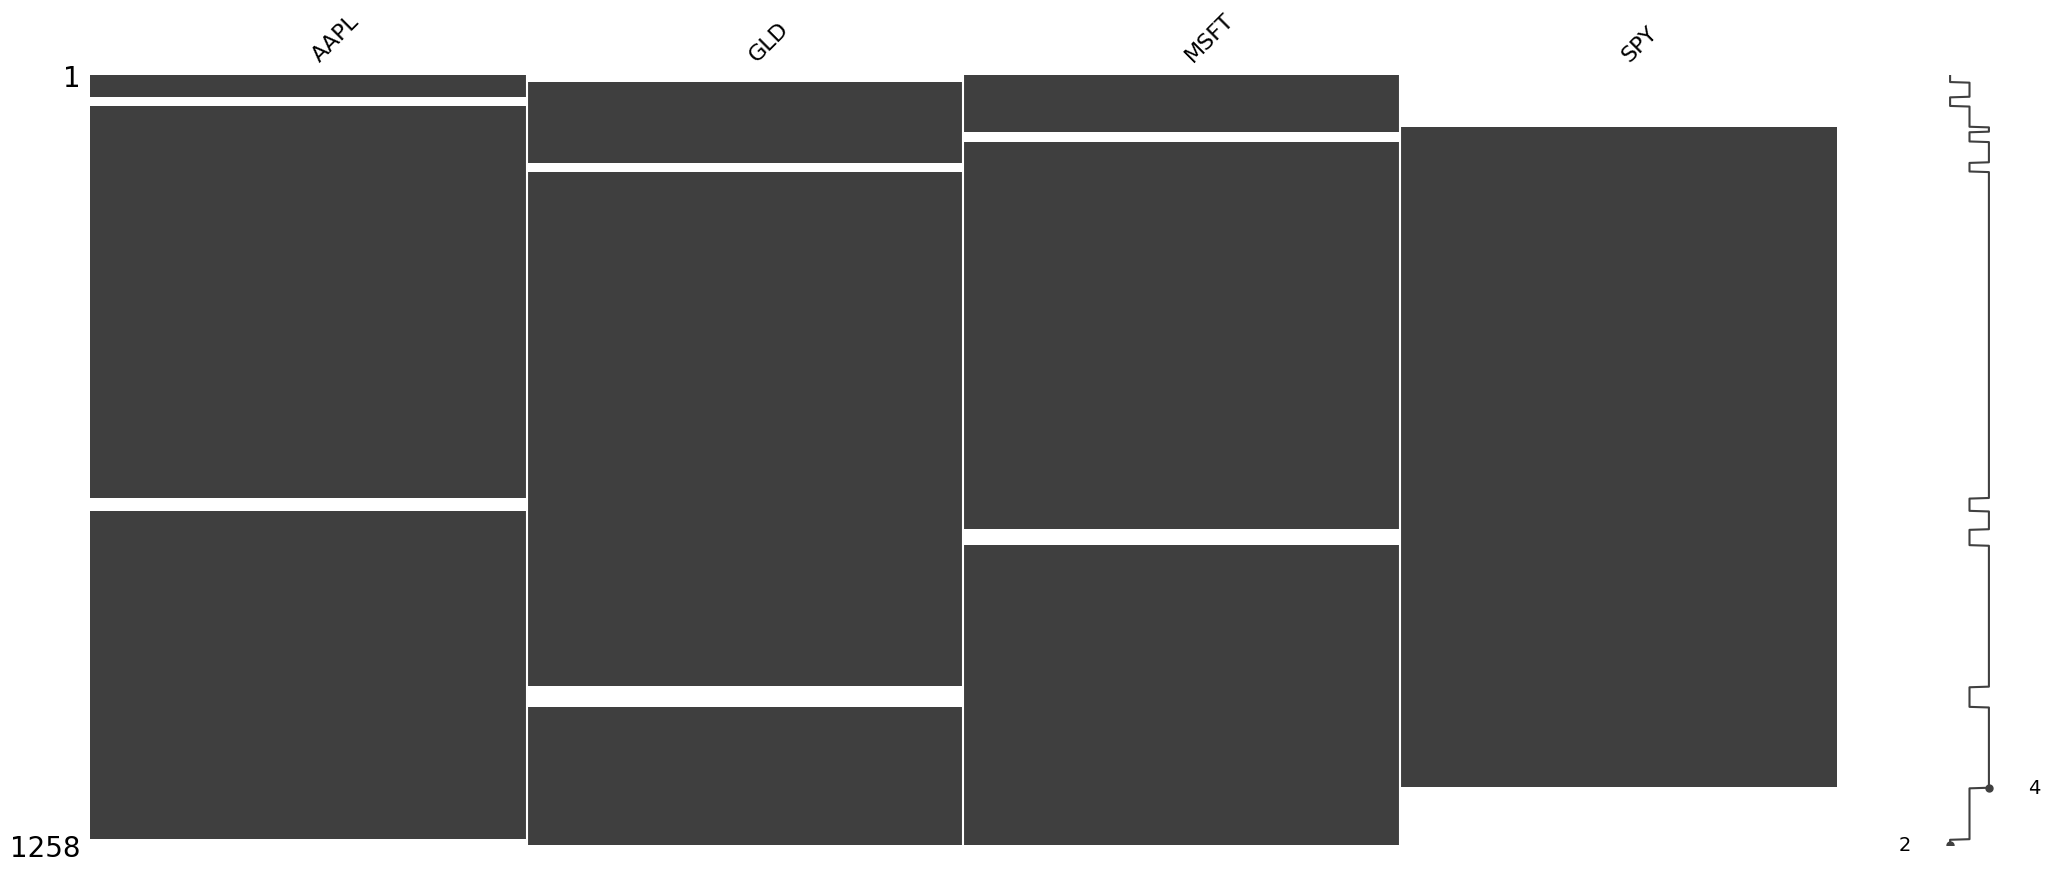

In [44]:
import missingno as mso

mso.matrix(data)

In [45]:
# Contamos el número de nulos en cada columna.
data.isnull().sum()

,0
AAPL,46
GLD,60
MSFT,42
SPY,179


## EJERCICIO: Análisis inicial de Series de Precios de Activos Financieros:

1- **Descarga de Datos**:

  Descarga los archivos de precios históricos de tres activos financieros diferentes (AAPL.xlsx, MSFT.xlsx y CSCO.csv).

2- **Concatenación de datos**

  Selecciona únicamente la columna Cierre Ajustado de cada DataFrame, renombrándolas para que representen el ticker de cada activo (AAPL, MSFT, y CSCO).

    Junta todos en un único dataframe

3- **Inspección Inicial**:

  Muestra las primeras 10 filas del DataFrame resultante para revisar la estructura y contenido de los datos.

  Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.

4- **Slicing de datos**:

  Realiza un slicing para seleccionar solo las filas correspondientes al año 2024.

  Crea una nueva tabla que contenga los datos de precios de cierre de los activos seleccionados para las primeras 60 observaciones de 2024.

5- **Análisis Exploratorio Básico**:

  Calcula el número de días en los que los precios de cierre estuvieron disponibles para cada activo en 2024.

  Calcula la media de los precios de cierre para cada activo durante el año 2024, ignorando los valores nulos.

6- **Exportación de Datos**:

  Guarda el DataFrame final en un nuevo archivo CSV llamado precios_consolidados_2024.csv.

1- **Descarga de Datos**:

  Descarga los archivos de precios históricos de tres activos financieros diferentes (AAPL.xlsx, MSFT.xlsx y CSCO.csv).

In [46]:
file_path_AAPL = 'https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/raw/main/Modulo_02_Aplicaciones_Financieras/data/AAPL.xlsx'
file_path_MSFT = 'https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/raw/main/Modulo_02_Aplicaciones_Financieras/data/MSFT.xlsx'
file_path_CSCO = 'https://github.com/alfonso-santos/Introduccion-a-Python-para-las-Finanzas-2024/raw/main/Modulo_02_Aplicaciones_Financieras/data/CSCO.csv'

# 1. Cargar los datos desde los archivos en el directorio '../data' y establecer la columna 'Date' como índice
df_aapl = pd.read_excel(file_path_AAPL, index_col='Date', parse_dates=True)
df_msft = pd.read_excel(file_path_MSFT, index_col='Date', parse_dates=True)
df_csco = pd.read_csv(file_path_CSCO, index_col='Date', parse_dates=True)

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2022-01-03,177.830002,182.880005,177.710007,182.009995,179.273590,104487900
2022-01-04,182.630005,182.940002,179.119995,179.699997,176.998337,99310400
2022-01-05,179.610001,180.169998,174.639999,174.919998,172.290207,94537600
2022-01-06,172.699997,175.300003,171.639999,172.000000,169.414108,96904000
2022-01-07,172.889999,174.139999,171.029999,172.169998,169.581543,86709100
...,...,...,...,...,...,...
2024-09-09,220.820007,221.270004,216.710007,220.910004,220.910004,67180000
2024-09-10,218.919998,221.479996,216.729996,220.110001,220.110001,51591000
2024-09-11,221.460007,223.089996,217.889999,222.660004,222.660004,44587100


2- **Concatenación de datos**

  Selecciona únicamente la columna Cierre Ajustado de cada DataFrame, renombrándolas para que representen el ticker de cada activo (AAPL, MSFT, y CSCO).

  Junta todos en un único dataframe

3- **Inspección Inicial**:

  Muestra las primeras 10 filas del DataFrame resultante para revisar la estructura y contenido de los datos.

  Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.

,AAPL,MSFT,CSCO
Date,,,
2022-01-03,179.273590,NaN,NaN
2022-01-04,176.998337,NaN,NaN
2022-01-05,172.290207,NaN,NaN
2022-01-06,169.414108,NaN,NaN
2022-01-07,169.581543,NaN,NaN
2022-01-10,169.601257,NaN,NaN
2022-01-11,172.447815,NaN,NaN
2022-01-12,172.891037,NaN,NaN
2022-01-13,169.601257,NaN,NaN


,0
AAPL,0
MSFT,251
CSCO,156


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 678 entries, 2022-01-03 to 2024-09-13
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    678 non-null    float64
 1   MSFT    427 non-null    float64
 2   CSCO    522 non-null    float64
dtypes: float64(3)
memory usage: 21.2 KB


,AAPL,MSFT,CSCO
count,678.000000,427.000000,522.000000
mean,170.866642,354.692213,46.838985
std,23.752284,62.074594,3.887891
min,123.855095,219.158356,37.182934
25%,152.270084,316.031372,44.764562
50%,170.221504,357.844025,47.086695
75%,185.199730,411.318283,49.259592
max,234.548523,466.718781,56.040001


4- **Slicing de datos**:

  Realiza un slicing para seleccionar solo las filas correspondientes al año 2024.

  Crea una nueva tabla que contenga los datos de precios de cierre de los activos seleccionados para las primeras 60 observaciones de 2024.

In [54]:
# Selecciono los datos de 2024



In [55]:
# Selecciono los datos de 2024 y los primeros 60 días



,AAPL,MSFT,CSCO
Date,,,
2024-01-02,184.938217,368.854095,49.291550
2024-01-03,183.553482,368.585571,49.675102
2024-01-04,181.222336,365.940002,49.252216
2024-01-05,180.495071,365.751038,49.262051
2024-01-08,184.858521,372.653351,49.625935
2024-01-09,184.440109,373.747345,49.085026
2024-01-10,185.486145,380.689423,49.409573
2024-01-11,184.888412,382.539307,49.606262
2024-01-12,185.217163,386.358429,49.507919


5- **Análisis Exploratorio Básico**:

  Calcula el número de días en los que los precios de cierre estuvieron disponibles para cada activo en 2024.

  Calcula la media de los precios de cierre para cada activo durante el año 2024, ignorando los valores nulos.

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 177 entries, 2024-01-02 to 2024-09-13
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    177 non-null    float64
 1   MSFT    177 non-null    float64
 2   CSCO    124 non-null    float64
dtypes: float64(3)
memory usage: 5.5 KB


,0
AAPL,195.430356
MSFT,416.357165
CSCO,48.046718


,AAPL,MSFT,CSCO
count,177.000000,177.000000,124.000000
mean,195.430356,416.357165,48.046718
std,21.081554,19.556515,1.465662
min,164.585999,365.751038,45.133335
25%,180.296478,405.097839,47.024632
50%,189.620514,414.005676,48.065247
75%,217.708008,424.746948,49.156325
max,234.548523,466.718781,51.465023


## 4. Limpieza de datos

¿Qué podemos hacer ahora?
* Eliminar las filas que no contienen datos.
* Rellenar los datos faltantes.
* Remuestrear los datos a una frecuencia menor.
* Obtener los datos desde una fuente de datos más fiable.

Eliminar las filas que no contienen datos

<Axes: >

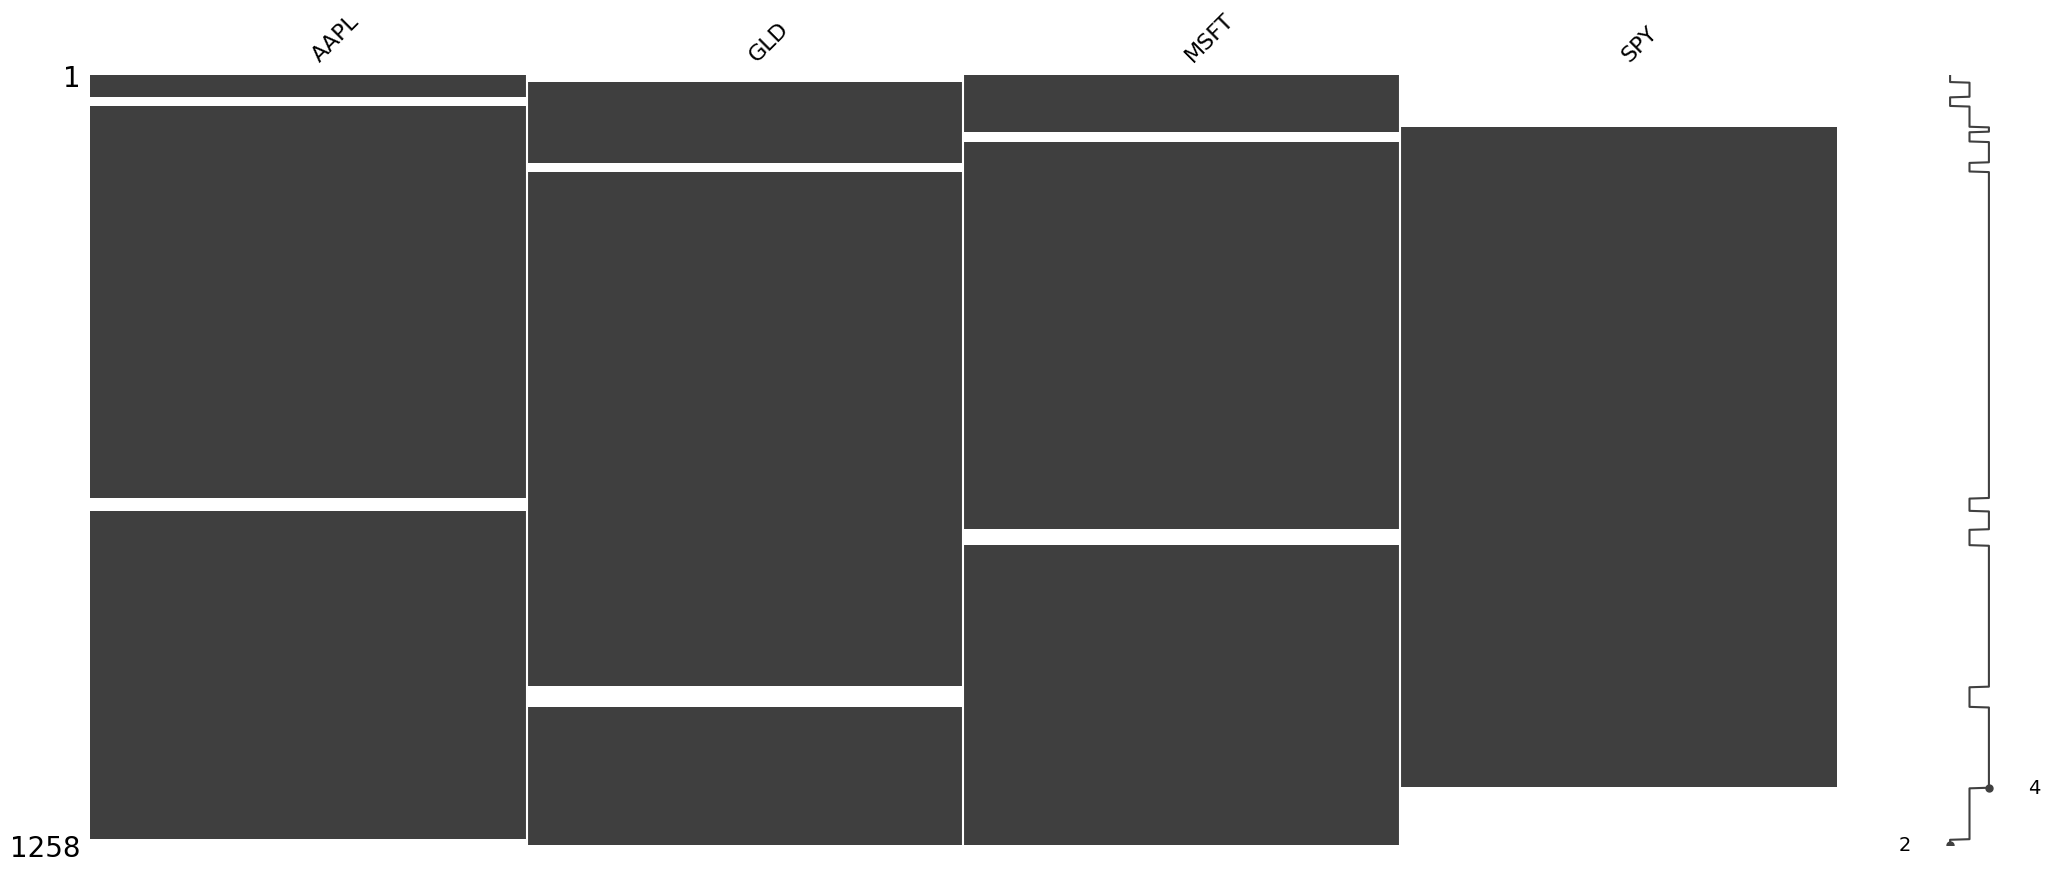

In [59]:
# Veamos los datos


`data.dropna(how="any",axis=1)`
Borra las columnas que tenga al menos un NaN


Tengo dos opciones para `how`:

how="any" → elimina si hay al menos un NaN

how="all" → elimina solo si todos los valores son NaN

""
Date
2019-07-01
2019-07-02
2019-07-03
2019-07-05
2019-07-08
...
2024-06-24
2024-06-25
2024-06-26


<Axes: >

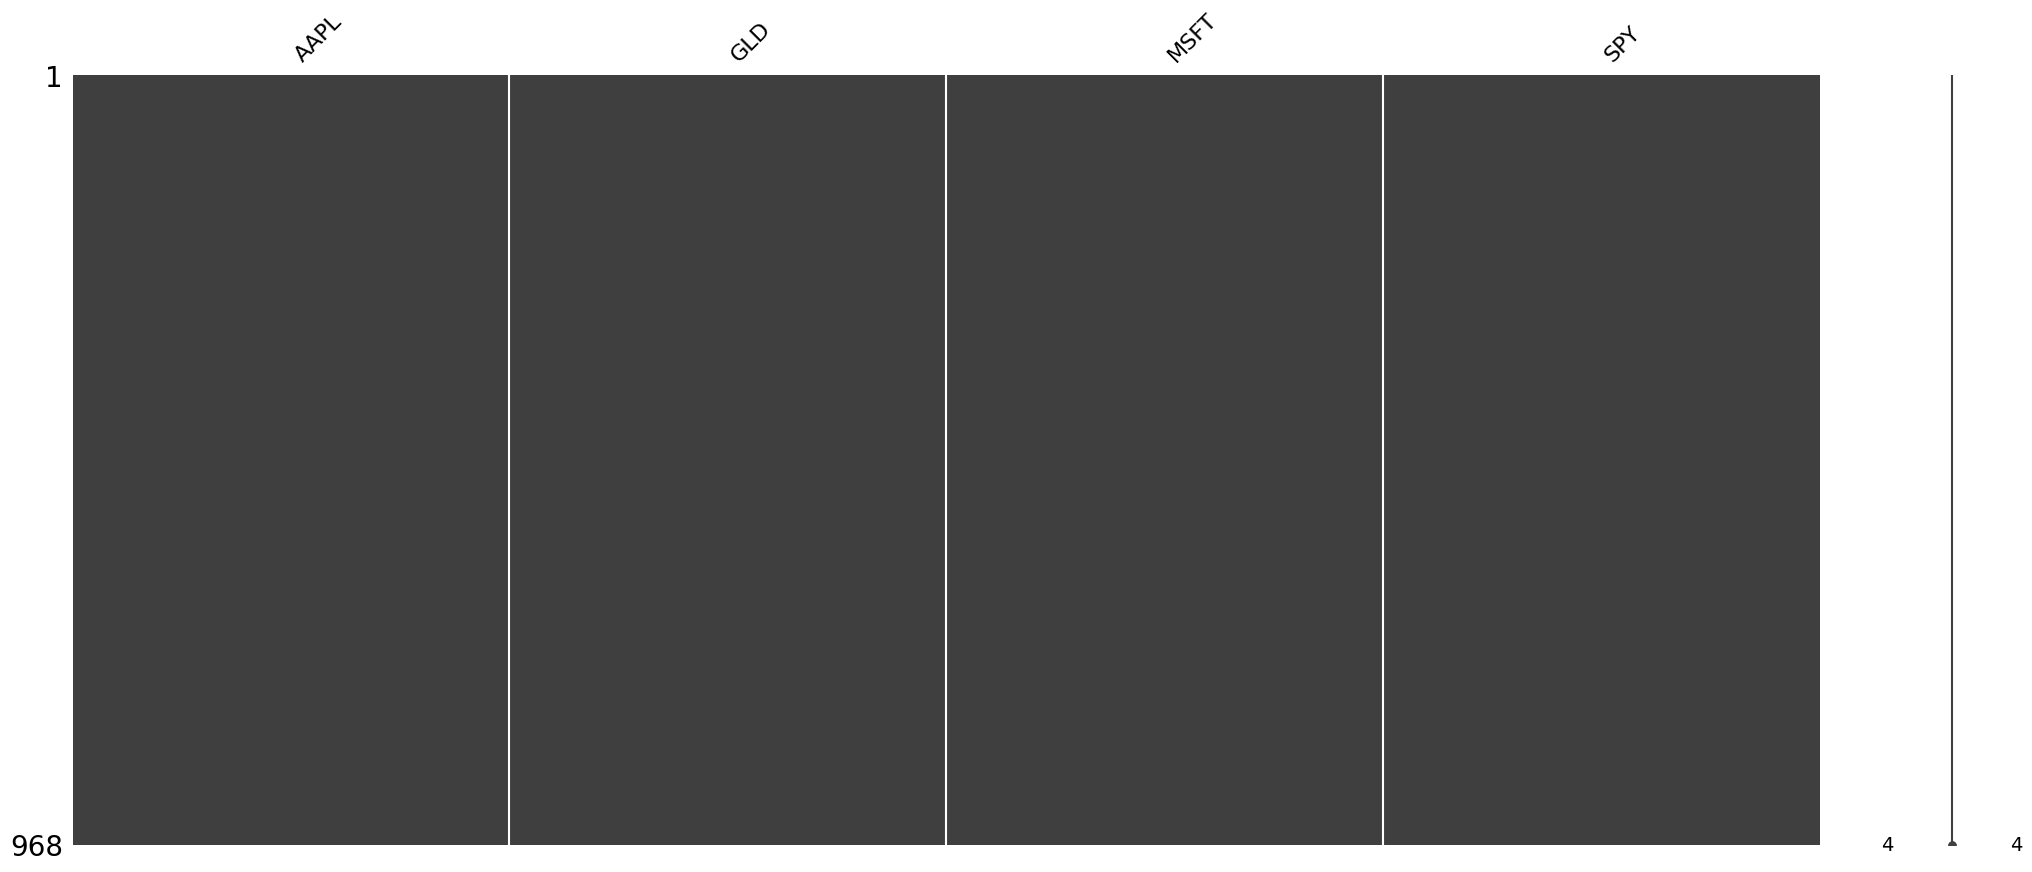

In [61]:
# Eliminamos las filas que tengan al menos un valor nulo.


Rellenar datos faltantes.

**Cuidado con rellenar datos... depende del caso de uso en el que se está trabajando.**

In [62]:
# Rellena los NaN de cada columna con un cero.
data.fillna(0)

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,0.000000,129.397415,0.0
2019-07-02,48.913532,0.000000,130.255753,0.0
2019-07-03,49.318890,0.000000,131.095001,0.0
2019-07-05,49.275448,0.000000,130.713547,0.0
2019-07-08,48.259693,0.000000,130.618149,0.0
...,...,...,...,...
2024-06-24,0.000000,215.630005,447.670013,0.0
2024-06-25,0.000000,214.559998,450.950012,0.0
2024-06-26,0.000000,212.580002,452.160004,0.0


In [63]:
# Rellena los NaN de cada columna con la media de cada columna.
data.fillna(data.mean())

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,171.328430,129.397415,380.759461
2019-07-02,48.913532,171.328430,130.255753,380.759461
2019-07-03,49.318890,171.328430,131.095001,380.759461
2019-07-05,49.275448,171.328430,130.713547,380.759461
2019-07-08,48.259693,171.328430,130.618149,380.759461
...,...,...,...,...
2024-06-24,134.902860,215.630005,447.670013,380.759461
2024-06-25,134.902860,214.559998,450.950012,380.759461
2024-06-26,134.902860,212.580002,452.160004,380.759461


In [64]:
# Rellena los NaN de cada columna con el último valor conocido hacia adelante.
data.ffill()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,NaN,129.397415,NaN
2019-07-02,48.913532,NaN,130.255753,NaN
2019-07-03,49.318890,NaN,131.095001,NaN
2019-07-05,49.275448,NaN,130.713547,NaN
2019-07-08,48.259693,NaN,130.618149,NaN
...,...,...,...,...
2024-06-24,214.240005,215.630005,447.670013,490.965698
2024-06-25,214.240005,214.559998,450.950012,490.965698
2024-06-26,214.240005,212.580002,452.160004,490.965698


In [65]:
# Rellena los NaN de cada columna con el último valor conocido hacia atrás.
data.bfill()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,136.479996,129.397415,282.404022
2019-07-02,48.913532,136.479996,130.255753,282.404022
2019-07-03,49.318890,136.479996,131.095001,282.404022
2019-07-05,49.275448,136.479996,130.713547,282.404022
2019-07-08,48.259693,136.479996,130.618149,282.404022
...,...,...,...,...
2024-06-24,NaN,215.630005,447.670013,NaN
2024-06-25,NaN,214.559998,450.950012,NaN
2024-06-26,NaN,212.580002,452.160004,NaN


In [66]:
# Rellena los NaN de cada columna con el último valor conocido primero hacia delante y luego hacia atrás.
data.ffill().bfill()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-01,48.628834,136.479996,129.397415,282.404022
2019-07-02,48.913532,136.479996,130.255753,282.404022
2019-07-03,49.318890,136.479996,131.095001,282.404022
2019-07-05,49.275448,136.479996,130.713547,282.404022
2019-07-08,48.259693,136.479996,130.618149,282.404022
...,...,...,...,...
2024-06-24,214.240005,215.630005,447.670013,490.965698
2024-06-25,214.240005,214.559998,450.950012,490.965698
2024-06-26,214.240005,212.580002,452.160004,490.965698


Remuestrear los datos a una frecuencia menor.

In [67]:
# Remuestrea los datos de días a semanas usando el último valor conocido el miércoles de cada semana.
data.resample("W-WED").last()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-03,49.318890,NaN,131.095001,NaN
2019-07-10,49.034176,NaN,131.466949,NaN
2019-07-17,49.063133,NaN,129.960129,NaN
2019-07-24,50.346706,134.369995,134.204056,NaN
2019-07-31,51.401085,133.210007,129.960129,NaN
...,...,...,...,...
2024-06-05,195.869995,217.820007,424.010010,NaN
2024-06-12,213.070007,214.720001,441.059998,NaN
2024-06-19,214.240005,215.470001,446.339996,NaN


In [68]:
data.resample("W-MON").last()   # lunes
data.resample("W-TUE").last()   # martes
data.resample("W-WED").last()   # miércoles
data.resample("W-THU").last()   # jueves
data.resample("W-FRI").last()   # viernes
data.resample("W-SAT").last()   # sábado
data.resample("W-SUN").last()   # domingo

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-07,49.275448,NaN,130.713547,NaN
2019-07-14,49.051064,NaN,132.468353,NaN
2019-07-21,48.879753,134.470001,130.293915,NaN
2019-07-28,50.122318,133.639999,134.795349,NaN
2019-08-04,49.224781,135.889999,130.560959,NaN
...,...,...,...,...
2024-06-02,192.250000,215.300003,415.130005,NaN
2024-06-09,196.889999,211.600006,423.850006,NaN
2024-06-16,214.240005,215.729996,442.570007,NaN


Otras frecuencias útiles

In [69]:
data.resample("D").last()       # diario
data.resample("B").last()       # día hábil
data.resample("W-FRI").last()   # semanal, viernes
data.resample("ME").last()      # fin de mes
data.resample("MS").first()     # inicio de mes
data.resample("QE").last()      # fin de trimestre
data.resample("YE").last()      # fin de año

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-12-31,71.332909,142.899994,151.412109,300.326996
2020-12-31,130.044678,178.360001,215.813828,355.381714
2021-12-31,175.102829,170.960007,329.066284,457.478516
2022-12-31,128.868332,169.639999,236.846252,374.330170
2023-12-31,192.024185,191.169998,374.670074,472.314026
2024-12-31,214.240005,215.009995,446.950012,490.965698


También puedes combinar resample() con distintas operaciones:

In [70]:
# Remuestrea los datos usando el último valor conocido en la fecha de fin de mes.
data.resample("ME").last()

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-31,51.401085,133.210007,129.960129,NaN
2019-08-31,50.947308,143.750000,131.914291,NaN
2019-09-30,54.243515,138.869995,133.033829,NaN
2019-10-31,60.247440,142.429993,137.186630,281.651917
2019-11-30,64.919876,137.860001,139.664993,291.847198
2019-12-31,71.332909,142.899994,151.412109,300.326996
2020-01-31,75.185577,147.119995,163.442474,300.205719
2020-02-29,66.561684,148.380005,155.975128,276.439667
2020-03-31,61.918247,148.050003,151.835297,241.920288


In [71]:
data.resample("ME").last()      # último dato del mes
data.resample("ME").first()     # primer dato del mes
data.resample("ME").mean()      # media mensual
data.resample("ME").max()       # máximo mensual
data.resample("ME").min()       # mínimo mensual
data.resample("ME").sum()       # suma mensual

,AAPL,GLD,MSFT,SPY
Date,,,,
2019-07-31,1089.295578,1343.239990,2897.575500,0.000000
2019-08-31,688.509792,3120.089996,2866.982132,0.000000
2019-09-30,693.637478,2841.209991,2643.175583,0.000000
2019-10-31,1310.638477,3240.119980,3064.160751,564.055939
2019-11-30,1274.672607,2771.409988,829.617203,5762.234375
2019-12-31,1410.635319,2931.819992,2821.728195,6201.088501
2020-01-31,1591.172050,2196.559998,3306.659668,6407.090729
2020-02-29,1439.326820,1524.550003,3263.893967,5803.945129
2020-03-31,1405.882038,3291.089981,3231.171600,5446.529068


Obtener los datos desde una fuente más fiable

**La API de YahooFinance** permite acceder programáticamente a datos financieros, incluidos precios históricos, cotizaciones en tiempo real, datos fundamentales y noticias de mercado.

Para más información de los datos que proporciona lo puedes ver en [Datos YahooFinance](https://python-yahoofinance.readthedocs.io/en/latest/)

In [72]:
pip install yfinance

In [73]:
import yfinance as yf

data = yf.download(["AAPL", "GLD", "MSFT", "SPY"], start="2018-12-31", end="2023-12-31")
data

/tmp/ipykernel_2193/2567231353.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(["AAPL", "GLD", "MSFT", "SPY"], start="2018-12-31", end="2023-12-31")
[*********************100%***********************]  4 of 4 completed


Price            Close                                            High  \
Ticker            AAPL         GLD        MSFT         SPY        AAPL   
Date                                                                     
2018-12-31   37.394249  121.250000   94.434525  223.019547   37.778289   
2019-01-02   37.436916  121.330002   94.016159  223.251556   37.657386   
2019-01-03   33.707924  122.430000   90.557457  217.924179   34.544754   
2019-01-04   35.146881  121.440002   94.769241  225.223740   35.215631   
2019-01-07   35.068661  121.860001   94.890106  226.999542   35.282019   
...                ...         ...         ...         ...         ...   
2023-12-22  191.268112  190.270004  366.750366  458.641022  193.056308   
2023-12-26  190.724777  191.720001  366.828735  460.577667  191.554656   
2023-12-27  190.823563  192.589996  366.251099  461.410431  191.169353   
2023-12-28  191.248398  191.470001  367.435760  461.584656  192.315391   
2023-12-29  190.210999  191.169998  368.179871  460.248352  192.058470   

Price                                                  Low              \
Ticker             GLD        MSFT         SPY        AAPL         GLD   
Date                                                                     
2018-12-31  121.260002   95.206217  223.260489   37.095548  120.830002   
2019-01-02  121.750000   94.601898  224.170704   36.562155  120.879997   
2019-01-03  122.459999   93.151455  221.814886   33.662881  121.730003   
2019-01-04  121.599998   95.308497  225.866243   34.089584  120.690002   
2019-01-07  122.220001   96.015101  228.400547   34.587424  121.570000   
...                ...         ...         ...         ...         ...   
2023-12-22  191.880005  367.337831  460.316212  190.645696  190.070007   
2023-12-26  191.740005  369.061077  461.478190  190.507426  190.399994   
2023-12-27  193.179993  367.220396  461.555672  188.788377  191.539993   
2023-12-28  192.889999  368.591089  462.417390  190.843333  191.440002   
2023-12-29  191.639999  369.276455  461.913850  189.420631  190.740005   

Price                                     Open                          \
Ticker            MSFT         SPY        AAPL         GLD        MSFT   
Date                                                                     
2018-12-31   93.383912  220.833258   37.581527  120.980003   94.174196   
2019-01-02   91.989307  219.476862   36.718617  121.349998   92.556454   
2019-01-03   90.371503  217.442295   34.132264  121.779999   93.067774   
2019-01-04   91.979997  220.565599   34.262639  121.320000   92.714499   
2019-01-07   93.885983  224.599081   35.251200  122.160004   94.499614   
...                ...         ...         ...         ...         ...   
2023-12-22  364.919458  456.752831  192.829068  191.600006  365.869184   
2023-12-26  365.692978  458.970266  191.278030  190.970001  367.161625   
2023-12-27  365.017426  459.841770  190.171524  191.770004  365.879037   
2023-12-28  366.339176  461.168289  191.801650  192.339996  367.523876   
2023-12-29  365.673383  458.302036  191.564492  190.990005  368.140698   

Price                      Volume                                 
Ticker             SPY       AAPL       GLD      MSFT        SPY  
Date                                                              
2018-12-31  222.698295  140014000   8449400  33173800  144299400  
2019-01-02  219.503631  148158800  12776200  35329300  126925200  
2019-01-03  221.511472  365248800  15440800  42579100  144140700  
2019-01-04  220.940390  234428400  13334000  44060600  142628800  
2019-01-07  225.491445  219111200   7473600  35656100  103139100  
...                ...        ...       ...       ...        ...  
2023-12-22  458.844359   37149600   7176300  17107500   67160400  
2023-12-26  459.047747   28919300   4502700  12673100   55387000  
2023-12-27  460.374330   48087700   5813300  14905400   68000300  
2023-12-28  461.768637   34049900   6171500  14327000   77158100  
2023-12-29  461.39

In [74]:
data = data.loc[:, "Close"]
data

Ticker,AAPL,GLD,MSFT,SPY
Date,,,,
2018-12-31,37.394249,121.250000,94.434525,223.019547
2019-01-02,37.436916,121.330002,94.016159,223.251556
2019-01-03,33.707924,122.430000,90.557457,217.924179
2019-01-04,35.146881,121.440002,94.769241,225.223740
2019-01-07,35.068661,121.860001,94.890106,226.999542
...,...,...,...,...
2023-12-22,191.268112,190.270004,366.750366,458.641022
2023-12-26,190.724777,191.720001,366.828735,460.577667
2023-12-27,190.823563,192.589996,366.251099,461.410431


In [75]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1259 entries, 2018-12-31 to 2023-12-29
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1259 non-null   float64
 1   GLD     1259 non-null   float64
 2   MSFT    1259 non-null   float64
 3   SPY     1259 non-null   float64
dtypes: float64(4)
memory usage: 49.2 KB


In [76]:
data.describe()

Ticker,AAPL,GLD,MSFT,SPY
count,1259.000000,1259.000000,1259.000000,1259.000000
mean,120.038790,162.905488,226.821684,349.683789
std,46.294755,18.664851,71.990889,65.173731
min,33.707924,119.940002,90.557457,203.911911
25%,74.447411,153.270004,164.429787,284.481430
50%,131.049622,167.770004,234.315262,366.689240
75%,156.233322,177.264999,282.351746,405.972458
max,195.723831,193.889999,374.700684,461.584656


## 5. Visualización

Hasta ahora hemos visto cómo descargar y limpiar los datos, pero nos falta un ejercicio importante que es el que más ayuda a analizar los datos: **visualizarlos**.

Veremos dos formas de visualizar datos:

- Usando los **métodos de visualización de Pandas** para un análisis rápido e inicial.

- Usando **Matplotlib** para crear gráficos más desarrollados y personalizados.

Para ver la documentación de cómo hacer gráficos con Pandas ver [Visualización con Pandas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/04_plotting.html)

Representa gráficamente los datos contenidos en el DataFrame data.
'data.plot(...)'

Pandas utilizará normalmente:
- el índice (Fecha) como eje X;
- las columnas (AAPL, MSFT, CSCO) como variables a representar.

<Axes: xlabel='Date'>

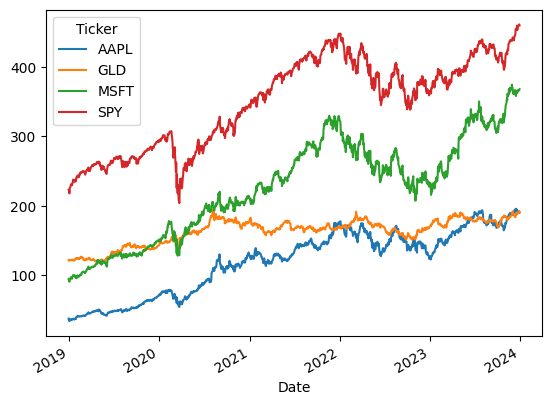

In [77]:
data.plot()

`figsize=(12, 4)`

Controla el tamaño de la figura: figsize=(ancho, alto), 12 pulgadas de ancho y 4 pulgadas de alto.

`subplots=True`

crea un gráfico diferente para cada columna

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

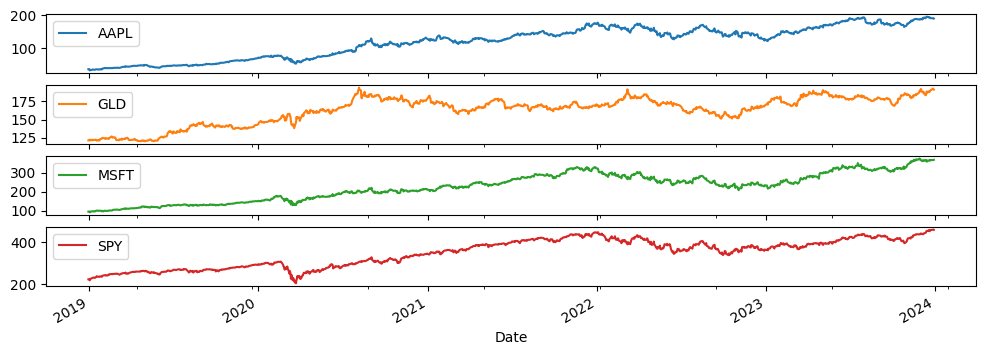

In [78]:
data.plot(figsize=(12, 4), subplots=True)

**Matplotlib** es una biblioteca de Python utilizada para crear gráficos y visualizaciones de datos en 2D. Es altamente configurable y permite generar gráficos de líneas, barras, dispersión, histogramas, entre otros, con opciones para personalizar colores, estilos y etiquetas.

Puedes encontrar la documentación en [matplotlib](https://matplotlib.org/)

En nuestro caso, ¿cómo puedo graficar estas series de precios?

In [79]:
import matplotlib.pyplot as plt

In [ ]:
plt.figure(figsize=(10,3)) # Indico el tamaño
plt.plot(data["AAPL"], label="AAPL") # Defino las leyendas
plt.plot(data["GLD"], label="GLD")
plt.plot(data["MSFT"], label="MSFT")
plt.plot(data["SPY"], label="SPY")
plt.title("Precios de cierre ajustados") #Defino el título
plt.grid(True) # Le pongo una rejilla
plt.legend() # le indico que refleje las leyendas
plt.show()

Por defecto `plt.legend(loc="upper right")`

Otras opciones:
- "upper right"
- "upper left"
- "lower right"
- "lower left"
- "center"
- "center left"
- "center right"
- "upper center"
- "lower center"
- "best"

Además puedo poner un título a leyenda:

`plt.legend(title="Activos")`

Determinar el tamaño de letra

`plt.legend(title="Activos", fontsize=10)`

Determinar el número de columnas

`plt.legend(ncol=2)`

Quitar o mantener recuadro

`plt.legend(frameon=False)`

Poner leyenda fuera del cuadro:

`bbox_to_anchor` permite posicionarla con más precisión.

`plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)`

Cambiar el tamaño de los marcadores, pero debo definir previamente un marcador.

`plt.legend(markerscale=2)`

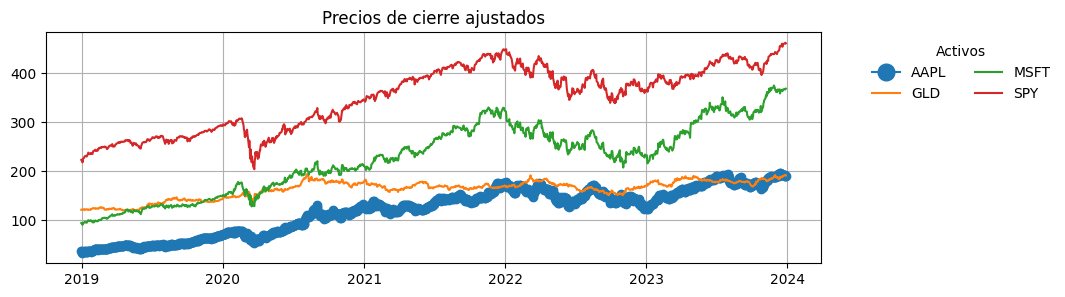

In [80]:
plt.figure(figsize=(10,3)) # Indico el tamaño
plt.plot(data["AAPL"], label="AAPL",marker="o") # Defino un marcados
plt.plot(data["GLD"], label="GLD")
plt.plot(data["MSFT"], label="MSFT")
plt.plot(data["SPY"], label="SPY")
plt.title("Precios de cierre ajustados") #Defino el título
plt.grid(True) # Le pongo una rejilla
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    title="Activos",
    fontsize=10,
    ncol=2,
    frameon=False,
    markerscale=2
)
plt.show()

Tipo de marcadores:
- marker="o"   # círculo
- marker="s"   # cuadrado
- marker="^"   # triángulo arriba
- marker="v"   # triángulo abajo
- marker="<"   # triángulo izquierda
- marker=">"   # triángulo derecha
- marker="D"   # rombo
- marker="d"   # rombo pequeño
- marker="*"   # estrella
- marker="+"   # cruz
- marker="x"   # aspa
- marker="p"   # pentágono
- marker="h"   # hexágono
- marker="H"   # hexágono alternativo
- marker="."   # punto
- marker=","   # píxel
- marker="1"   # tri_down
- marker="2"   # tri_up
- marker="3"   # tri_left
- marker="4"   # tri_right

## Ejercicio de Repaso: Análisis y Visualización de Datos Financieros

### Objetivos:
1. Descargar datos financieros de Yahoo Finance.
2. Realizar la inspección, limpieza y concatenación de datos.
3. Aplicar técnicas de slicing para análisis.
4. Visualizar los datos para un análisis preliminar.

### Instrucciones:

#### 1. Descarga y Preparación de Datos:
- Utiliza la librería `yfinance` para descargar el 'Adj Close' de los siguientes activos para el periodo del 1 de enero de 2015 al 31 de agosto de 2023:
  - Tesla, Inc. (TSLA)
  - NVIDIA Corporation (NVDA)
  - Meta Platforms, Inc. (META)
- Renombra las columnas de cada DataFrame utilizando el formato `Activo_Columna` (por ejemplo, `TSLA_AdjClose`, `NVDA_AdjClose`, etc.).
- Junta todos los DataFrames en un único DataFrame llamado `df_concatenado`, utilizando la fecha como índice.
- Después de la concatenación, crea un nuevo DataFrame llamado `df_adj_close` que contenga las columnas de precios ajustados (`Adj Close`) de cada activo.

#### 2. Inspección Inicial:
- Muestra las primeras 10 filas del DataFrame `df_adj_close` para revisar su estructura y contenido.
- Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.
- Utiliza `info()` y `describe()` para obtener una visión general de los datos.

#### 3. Slicing de Datos:
- Selecciona las filas correspondientes a los meses de julio de 2018, 2019, 2020, 2021 y 2022 y crea una nueva tabla con los precios ajustados (`Adj Close`) de esos periodo para cada activo.
- Crea una tabla con las primeras 30 observaciones del año 2023.

#### 4. Visualización de Datos:
- Genera un gráfico de líneas utilizando los métodos de visualización de pandas para mostrar la evolución de los precios ajustados de los tres activos durante el periodo completo.
- Utilizando `matplotlib`, crea un gráfico personalizado para visualizar los tres activos, incluyendo título, leyenda y cuadrícula.

#### 5. Interpretación:
- Razona en cuál de los activos analizados invertiría tu dinero.


#### 1. Descarga y Preparación de Datos:
- Utiliza la librería `yfinance` para descargar el 'Adj Close' de los siguientes activos para el periodo del 1 de enero de 2015 al 31 de agosto de 2023:
  - Tesla, Inc. (TSLA)
  - NVIDIA Corporation (NVDA)
  - Meta Platforms, Inc. (META)
- Renombra las columnas de cada DataFrame utilizando el formato `Activo_Columna` (por ejemplo, `TSLA_AdjClose`, `NVDA_AdjClose`, etc.).
- Junta todos los DataFrames en un único DataFrame llamado `df_concatenado`, utilizando la fecha como índice.
- Después de la concatenación, crea un nuevo DataFrame llamado `df_adj_close` que contenga las columnas de precios ajustados (`Adj Close`) de cada activo.



#### **Utilizamos diccionarios**

/tmp/ipykernel_2193/4227165761.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(activo, start=inicio, end=fin) # Descarga uno a uno
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2193/4227165761.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(activo, start=inicio, end=fin) # Descarga uno a uno
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2193/4227165761.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(activo, start=inicio, end=fin) # Descarga uno a uno
[*********************100%***********************]  1 of 1 completed


{'TSLA':                   TSLA
 Date                  
 2015-01-02   14.620667
 2015-01-05   14.006000
 2015-01-06   14.085333
 2015-01-07   14.063333
 2015-01-08   14.041333
 ...                ...
 2023-08-24  230.039993
 2023-08-25  238.589996
 2023-08-28  238.820007
 2023-08-29  257.179993
 2023-08-30  256.899994
 
 [2180 rows x 1 columns],
 'NVDA':                  NVDA
 Date                 
 2015-01-02   0.481884
 2015-01-05   0.473745
 2015-01-06   0.459382
 2015-01-07   0.458185
 2015-01-08   0.475420
 ...               ...
 2023-08-24  47.018684
 2023-08-25  45.877201
 2023-08-28  46.691696
 2023-08-29  48.634727
 2023-08-30  49.113258
 
 [2180 rows x 1 columns],
 'META':                   META
 Date                  
 2015-01-02   77.767075
 2015-01-05   76.518059
 2015-01-06   75.487114
 2015-01-07   75.487114
 2015-01-08   77.499428
 ...                ...
 2023-08-24  284.253784
 2023-08-25  283.014679
 2023-08-28  287.733215
 2023-08-29  295.395966
 2023-08-30  292.5311

dict

pandas.core.frame.DataFrame

,TSLA,NVDA,META
Date,,,
2015-01-02,14.620667,0.481884,77.767075
2015-01-05,14.006000,0.473745,76.518059
2015-01-06,14.085333,0.459382,75.487114
2015-01-07,14.063333,0.458185,75.487114
2015-01-08,14.041333,0.475420,77.499428
...,...,...,...
2023-08-24,230.039993,47.018684,284.253784
2023-08-25,238.589996,45.877201,283.014679
2023-08-28,238.820007,46.691696,287.733215


#### **Utiliza listas**

/tmp/ipykernel_2193/1899082704.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(activo, start=inicio, end=fin) # Descarga uno a uno
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2193/1899082704.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(activo, start=inicio, end=fin) # Descarga uno a uno
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2193/1899082704.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(activo, start=inicio, end=fin) # Descarga uno a uno
[*********************100%***********************]  1 of 1 completed


[            TSLA_close
 Date                  
 2015-01-02   14.620667
 2015-01-05   14.006000
 2015-01-06   14.085333
 2015-01-07   14.063333
 2015-01-08   14.041333
 ...                ...
 2023-08-24  230.039993
 2023-08-25  238.589996
 2023-08-28  238.820007
 2023-08-29  257.179993
 2023-08-30  256.899994
 
 [2180 rows x 1 columns],
             NVDA_close
 Date                  
 2015-01-02    0.481884
 2015-01-05    0.473745
 2015-01-06    0.459382
 2015-01-07    0.458185
 2015-01-08    0.475420
 ...                ...
 2023-08-24   47.018684
 2023-08-25   45.877201
 2023-08-28   46.691696
 2023-08-29   48.634727
 2023-08-30   49.113258
 
 [2180 rows x 1 columns],
             META_close
 Date                  
 2015-01-02   77.767075
 2015-01-05   76.518059
 2015-01-06   75.487114
 2015-01-07   75.487114
 2015-01-08   77.499428
 ...                ...
 2023-08-24  284.253784
 2023-08-25  283.014679
 2023-08-28  287.733215
 2023-08-29  295.395966
 2023-08-30  292.531158
 
 [2180

,TSLA_close,NVDA_close,META_close
Date,,,
2015-01-02,14.620667,0.481884,77.767075
2015-01-05,14.006000,0.473745,76.518059
2015-01-06,14.085333,0.459382,75.487114
2015-01-07,14.063333,0.458185,75.487114
2015-01-08,14.041333,0.475420,77.499428
...,...,...,...
2023-08-24,230.039993,47.018684,284.253784
2023-08-25,238.589996,45.877201,283.014679
2023-08-28,238.820007,46.691696,287.733215


#### **Sólo con la API**

[*********************100%***********************]  3 of 3 completed


Ticker,META,NVDA,TSLA
Date,,,
2015-01-02,77.767075,0.481884,14.620667
2015-01-05,76.518059,0.473745,14.006000
2015-01-06,75.487114,0.459382,14.085333
2015-01-07,75.487114,0.458185,14.063333
2015-01-08,77.499428,0.475420,14.041333
...,...,...,...
2023-08-24,284.253784,47.018684,230.039993
2023-08-25,283.014679,45.877201,238.589996
2023-08-28,287.733215,46.691696,238.820007


#### 2. Inspección Inicial:
- Muestra las primeras 10 filas del DataFrame `df_adj_close` para revisar su estructura y contenido.
- Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.
- Utiliza `info()` y `describe()` para obtener una visión general de los datos.


Primeras 10 filas de df_adj_close:
Ticker           META      NVDA       TSLA
Date                                      
2015-01-02  77.767075  0.481884  14.620667
2015-01-05  76.518059  0.473745  14.006000
2015-01-06  75.487114  0.459382  14.085333
2015-01-07  75.487114  0.458185  14.063333
2015-01-08  77.499428  0.475420  14.041333
2015-01-09  77.063263  0.477336  13.777333
2015-01-12  76.052147  0.471351  13.480667
2015-01-13  75.784492  0.470633  13.616667
2015-01-14  75.615974  0.472548  12.846000
2015-01-15  73.405403  0.469196  12.791333


Valores nulos por columna:
Ticker
META    0
NVDA    0
TSLA    0
dtype: int64


Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2180 entries, 2015-01-02 to 2023-08-30
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   META    2180 non-null   float64
 1   NVDA    2180 non-null   float64
 2   TSLA    2180 non-null   float64
dtypes: float64(3)
memory usage: 68.1 KB


Estadísticas descriptivas:
Ticker         META         NVDA         TSLA
count   2180.000000  2180.000000  2180.000000
mean     183.712528     9.738864    97.506715
std       72.711036     9.972612   109.489916
min       73.405403     0.458185     9.578000
25%      127.559830     2.583307    16.539999
50%      173.159378     5.672168    22.779000
75%      217.951057    14.497872   200.935001
max      378.853058    49.113258   409.970001


#### 3. Slicing de Datos:
- Selecciona las filas correspondientes a los meses de julio de 2018, 2019, 2020, 2021 y 2022 y crea una nueva tabla con los precios ajustados de esos periodo para cada activo.
- Crea una tabla con las primeras 30 observaciones del año 2023.


Ticker,META,NVDA,TSLA
Date,,,
2018-07-02,195.641968,5.982333,22.337999
2018-07-03,191.052246,5.848975,20.724001
2018-07-05,196.722458,5.994432,20.610666
2018-07-06,201.460846,6.108035,20.593332
2018-07-09,202.957703,6.155450,21.233999
...,...,...,...
2022-07-25,165.199280,16.957893,268.433319
2022-07-26,157.764572,16.468801,258.859985
2022-07-27,168.103775,17.720919,274.820007



Primeras 30 observaciones de 2023:
Ticker            META       NVDA        TSLA
Date                                         
2023-01-03  123.654129  14.267299  108.099998
2023-01-04  126.261223  14.699851  113.639999
2023-01-05  125.834984  14.217466  110.339996
2023-01-06  128.888168  14.809485  113.059998
2023-01-09  128.342941  15.575923  119.769997
2023-01-10  131.832336  15.855988  118.849998
2023-01-11  131.733185  15.947679  123.220001
2023-01-12  135.519943  16.455978  123.559998
2023-01-13  135.787552  16.842690  122.400002
2023-01-17  134.181671  17.643015  131.490005
2023-01-18  131.862061  17.319099  128.779999
2023-01-19  134.964798  16.709131  127.169998
2023-01-20  138.156784  17.779558  133.419998
2023-01-23  142.022812  19.129042  143.750000
2023-01-24  141.893951  19.200804  143.889999
2023-01-25  140.268219  19.258610  144.429993
2023-01-26  146.017746  19.736013  160.270004
2023-01-27  150.419083  20.297138  177.899994
2023-01-30  145.779800  19.098150  166.66000

**RECORDATORIO**

`df_primero_30 = df_2023.iloc[:30]` como solo hemos puesto un selector, Pandas interpreta que te refieres a las filas.

#### 4. Visualización de Datos:
- Genera un gráfico de líneas utilizando los métodos de visualización de pandas para mostrar la evolución de los precios ajustados de los tres activos durante el periodo completo.
- Utilizando `matplotlib`, crea un gráfico personalizado para visualizar los tres activos, incluyendo título, leyenda y cuadrícula.

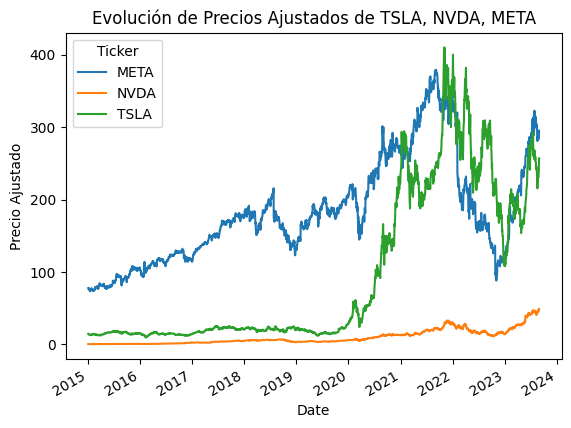

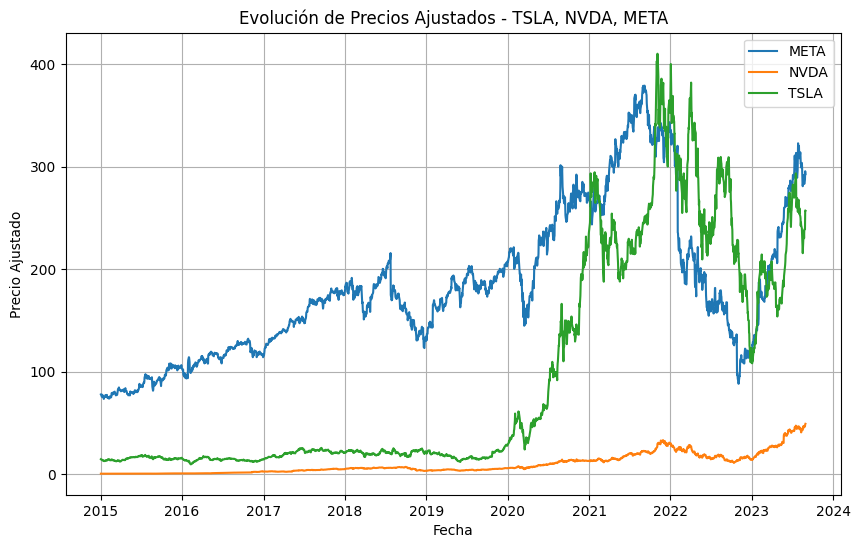